In [1]:
import logging

logging.basicConfig(level=logging.INFO, force=True)


from networkx.drawing import (
    draw as nx_draw,
    kamada_kawai_layout,
)
from networkx import get_node_attributes, connected_components
from networkx import nx_agraph
from mupt.graphs.generators import balanced_dendrimer_graph

from mupt.trees.subselect import NodePredicate
from mupt.mupr.primitives import (
    Primitive,
    RootPrimitive,
)
from mupt.mupr.properties import is_subdominant

from mupt.interfaces.smiles import primitive_from_smiles
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

INFO:rdkit:Enabling RDKit 2026.09.1 jupyter extensions
INFO:freud.msd:Using SciPy's fftpack for FFTs


# PAMAM dendrimer

## Assemble MuPT repr

In [2]:
num_generations: int = 3
lexicon = {  # notice the values are Primitive instances; applied even if not all-atom
    "cyanogen": primitive_from_smiles(
        "[N:1](-[*:2])(-[*:2])CC[N:1](-[*:2])(-[*:2])", label="_C"
    ),
    "AAm": primitive_from_smiles(
        "[*:1]-[C:2]C(=O)NCC[N:1](-[*:2])(-[*:2])", label="_A"
    ),
    "AAm_T": primitive_from_smiles("[*:1]-[C:2]C(=O)NCC[NH2]", label="_B"),
}

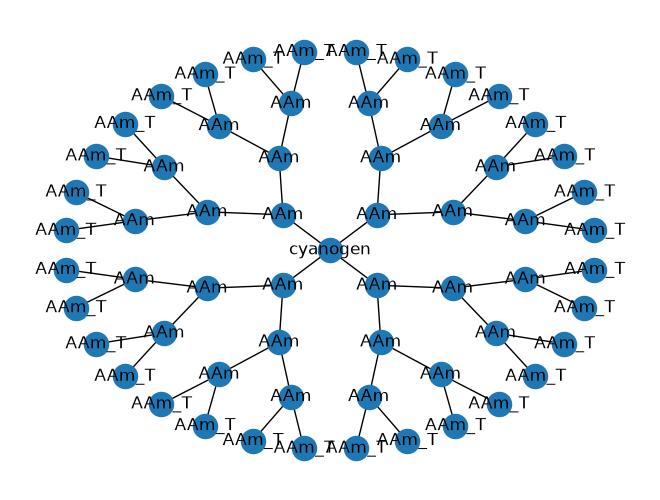

In [3]:
dendr = balanced_dendrimer_graph(
    coord_number=(lexicon["AAm"].functionality - 1),
    coord_number_core=lexicon["cyanogen"].functionality,
    num_generations=num_generations,
    core="cyanogen",
    shell_inner="AAm",
    shell_outer="AAm_T",
)

nx_draw(
    dendr,
    pos=nx_agraph.graphviz_layout(dendr, prog="twopi"),
    with_labels=True,
    labels=get_node_attributes(dendr, "label"),
)

### Select, connect, then inspect

In [4]:
# predicate : NodePredicate[Primitive] = lambda prim: isinstance(prim, CompositePrimitive)
# predicate : NodePredicate[Primitive] = lambda prim : is_atom(prim) and prim.element.symbol != 'H'
predicate: NodePredicate[Primitive] = is_subdominant

In [5]:
molprim = RootPrimitive()
molprim.populate_from_topology_and_lexicon(dendr, lexicon, label_attr="label")
xsec = molprim.cross_section(predicate)

print(f"{len(list(connected_components(xsec)))} molecules")

INFO:mupt.mupr.connection.linking:Paired up 60 new edges after 1 iteration(s); 0/60 edges remain unpaired
INFO:mupt.mupr.connection.linking:Linking protocol successful! 60/60 edges were assigned Connector pairings


1 molecules


In [6]:
# NOTE: this is the rate-limiting step here; not actually necessary for
# system setup, only for embedding nice-to-look-at positions.
# Will eventually be replaced w/ rigid/random walk initial coord gen
pos = kamada_kawai_layout(xsec, dim=2)

<Axes: >

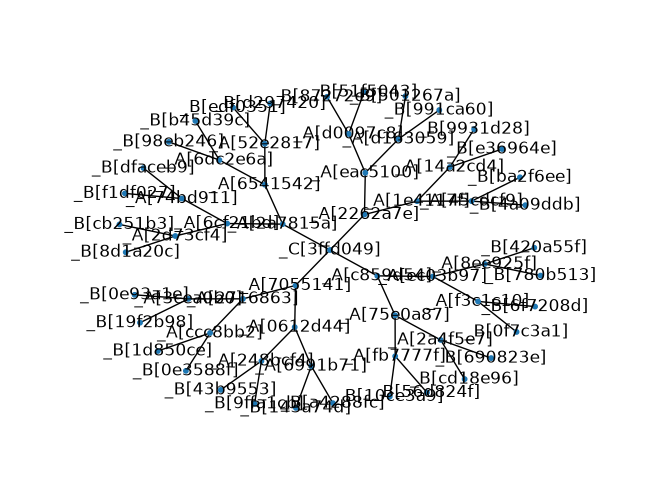

In [7]:
molprim.visualize_cross_section(
    xsec,
    pos=pos,
    with_labels=True,
    node_size=10,
)

## Export to mbuild

In [8]:
compound = primitive_to_mbuild(molprim, predicate=predicate)
...  # insert downstream code here
print(compound)

<ROOT 61 particles, 60 bonds, non-periodic, id: 10875988224>


In [9]:
import warnings

warnings.filterwarnings("ignore")
from flowermd.base import Molecule

molecules = Molecule(
    num_mols=1, compound=compound, name="PAMAM", identify_connections=False
)

INFO:numexpr.utils:NumExpr defaulting to 11 threads.


In [10]:
molecules.molecules

[<PAMAM 61 particles, 60 bonds, non-periodic, id: 10935029584>]

In [11]:
from flowermd.library import RandomWalk
import unyt as u

ref_length = 1.0 * u.Unit("nm")
ref_mass = 1.0 * u.Unit("g/mol")
ref_energy = 1.0 * u.Unit("kcal / mol")
ref_values_dict = {"length": ref_length, "mass": ref_mass, "energy": ref_energy}

system = RandomWalk(
    molecules=molecules,
    density=0.8 * u.Unit("nm**-3"),
    bond_length=1.0,
    base_units=ref_values_dict,
    seed=456,
)
system.box

Box: Lx=4.240463, Ly=4.240463, Lz=4.240463, xy=0.000000, xz=0.000000, yz=0.000000, 

In [12]:
from flowermd.library import Bead_Spring_DPD #check which xml your environment is pointing at
import hoomd

nlist = hoomd.md.nlist.Cell(buffer=0.4, exclusions=["bond"])
system.apply_forcefield(
    force_field=Bead_Spring_DPD(), kT=1.0, r_cut=1.01, nlist=nlist
)

In [13]:
from flowermd.library import PhantomWalk
import hoomd

sim = PhantomWalk(
    initial_state=system.hoomd_snapshot,
    forcefield=system.hoomd_forcefield,
    gsd_write_freq=100,
    log_write_freq=50,
    n_steps_dpd=500,
    n_steps_fire=100,
    write_at_start=True,
)

for writer in sim.operations.writers:
    if isinstance(writer, hoomd.write.GSD):
        writer.flush()

Initializing simulation state from a gsd.hoomd.Frame.
Step 75 of 500; TPS: 665.37; ETA: 0.0 minutes
Step 150 of 500; TPS: 1306.44; ETA: 0.0 minutes
Step 225 of 500; TPS: 1929.91; ETA: 0.0 minutes
Step 300 of 500; TPS: 2539.04; ETA: 0.0 minutes
Step 375 of 500; TPS: 3136.47; ETA: 0.0 minutes
Step 450 of 500; TPS: 3721.71; ETA: 0.0 minutes
Step 25 of 100; TPS: 225225.23; ETA: 0.0 minutes
The closest particles after DPD + FIRE are:  1.002750039100647


INFO:gsd.fl:opening file: trajectory.gsd with mode: r
INFO:gsd.hoomd:opening HOOMDTrajectory: <gsd.fl.GSDFile object at 0x11d78cd90>
INFO:gsd.hoomd:found 7 frames
INFO:gsd.fl:closing file: trajectory.gsd
INFO:gsd.fl:opening file: trajectory.gsd with mode: r
INFO:gsd.hoomd:opening HOOMDTrajectory: <gsd.fl.GSDFile object at 0x11d78e860>
INFO:gsd.hoomd:found 7 frames
INFO:gsd.fl:closing file: trajectory.gsd


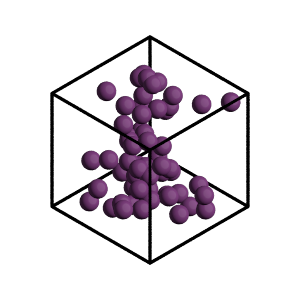

In [14]:
from cmeutils.visualize import FresnelGSD

sim_visualizer = FresnelGSD(
    gsd_file="trajectory.gsd", frame=0, view_axis=(1, 1, 1)
)
sim_visualizer.view()

INFO:gsd.fl:opening file: trajectory.gsd with mode: r
INFO:gsd.hoomd:opening HOOMDTrajectory: <gsd.fl.GSDFile object at 0x28aafdcc0>
INFO:gsd.hoomd:found 7 frames
INFO:gsd.fl:closing file: trajectory.gsd


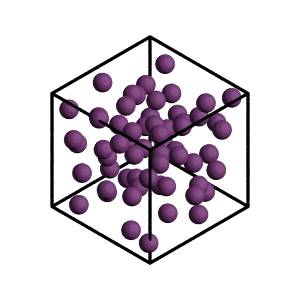

In [15]:
sim_visualizer.frame = -1
sim_visualizer.view()

In [16]:
snap = sim.state.get_snapshot()

In [17]:
snap.particles.position

array([[-0.6739495 , -0.23043611, -1.77519531],
       [-1.43211508, -0.77885584,  2.11259273],
       [-1.43406287, -0.50311527,  1.15128952],
       [-1.76216756, -1.15693812, -1.26292906],
       [-1.72969969, -0.53673513,  0.19645661],
       [-1.20693932,  0.25588486,  0.54111002],
       [ 1.71691901, -1.22451698, -0.61821334],
       [-1.61539238, -1.60540597, -0.38128466],
       [ 1.82964476, -0.18293708,  0.83741385],
       [ 2.11143643, -1.18907356,  0.84064601],
       [-1.11774956,  1.00635072,  1.19603824],
       [-1.91862483,  0.95824004,  0.55085848],
       [ 0.74146042, -1.10121773, -0.43601159],
       [ 1.22333485, -1.92627006, -0.10447334],
       [-1.91816821, -2.09867529,  0.4341205 ],
       [-1.06644853,  1.79925679, -0.3911258 ],
       [ 0.05056754,  0.3123482 ,  2.04051275],
       [ 0.77220308,  0.96328197,  1.80484524],
       [ 0.97051391, -0.07512702,  2.10013335],
       [ 1.32835581,  1.73408456,  2.11557723],
       [-0.1178198 ,  1.27238646,  1.469